# Replikasi Jurnal: Prediksi Penyakit Jantung Menggunakan Algoritma Support Vector Machine (SVM)

**Referensi Jurnal:**
- **Judul:** *Implementasi Machine Learning Untuk Prediksi Penyakit Jantung Menggunakan Algoritma Support Vector Machine*
- **Penulis:** Rahmat Hidayat, Yandiko Saputra Sy, Teguh Sujana, Mirdatul Husnah, Haris Tri Saputra, Finanta Okmayura
- **Publikasi:** BIOS : Jurnal Teknologi Informasi dan Rekayasa Komputer, Vol. 5, No. 2, September 2024, hlm. 161–168
- **Dataset:** `data/heart.csv` (1025 baris, 14 kolom)

Notebook ini menampilkan hasil replikasi SVM linear, laporan klasifikasi dan matriks konfusi.

## 1. Import Library

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 2. Pengumpulan & Eksplorasi Dataset

Pada **Bagian 2.1 & 3.1** jurnal dijelaskan bahwa dataset `heart.csv` memiliki:
- **1025 baris** total
- **499 baris** kelas `0` (tidak penyakit jantung)
- **526 baris** kelas `1` (penyakit jantung)
- **14 kolom** (13 fitur + 1 kolom `target`)

In [2]:
paths = [Path(folder) / name for folder in ('.', 'data', '../data') for name in ('heart.csv', 'heart.xls')]
data_path = next((p for p in paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Unggah heart.csv atau heart.xls sebelum menjalankan notebook.')
df = pd.read_csv(data_path)
print('Ukuran dataset:', df.shape)

Ukuran dataset: (1025, 14)


In [3]:
print('Nilai kosong:', df.isna().sum().sum())
print('Baris duplikat:', df.duplicated().sum())

Nilai kosong: 0
Baris duplikat: 723


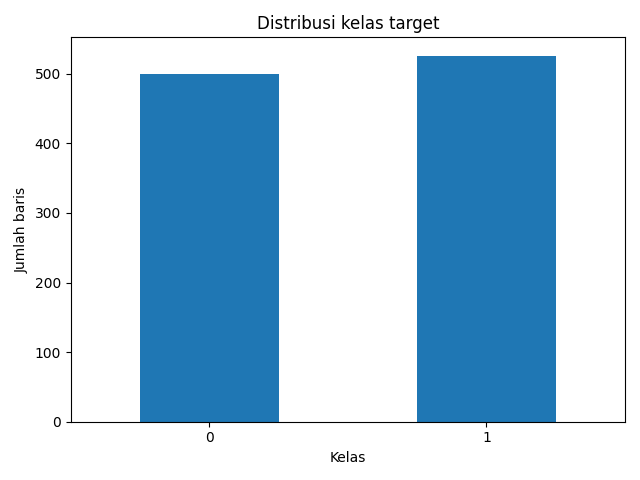

In [4]:
df['target'].value_counts().sort_index().plot.bar(rot=0, xlabel='Kelas', ylabel='Jumlah baris', title='Distribusi kelas target')
plt.tight_layout()
plt.show()

## 3. Persiapan Data (*Train-Test Split*)

> **Catatan Kajian:** Replikasi menggunakan 80% data latih dan 20% data uji, random_state=0. StandardScaler mempelajari skala fitur dari data latih.

In [5]:
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print('Jumlah data latih dan uji:', len(X_train), len(X_test))

Jumlah data latih dan uji: 820 205


## 4. Pembentukan *Learning Model* (SVM)

Pada **Bagian 3.2 (Kode 1)** jurnal, model dibentuk dengan kode berikut:
```python
clf = svm.SVC(kernel='linear')
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
```



In [6]:
clf = svm.SVC(kernel='linear')
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

## 5. Evaluasi Model

Pada **Bagian 3.2 (Kode 2)** jurnal, evaluasi dilakukan dengan kode berikut:
```python
accuracy = accuracy_score(y_test, y_pred)
print("Akurasi:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
```

Hasil yang dilaporkan pada **Tabel 3** jurnal:
- **Precision:** `0.93`
- **Recall:** `0.76`
- **F1-score:** `0.83`
- **Accuracy:** `0.85`

> **Catatan Kajian:** Pada rumus di Bagian 2.3 jurnal tertulis $f\text{-}1 = \frac{2 \times precision \times recall}{(precision \times recall)}$ (terdapat salah ketik operator perkalian di penyebut; seharusnya `precision + recall`). Fungsi `classification_report` di `scikit-learn` menghitung F1-score dengan rumus yang benar.

In [7]:
print(f'Akurasi: {accuracy_score(y_test, y_pred):.2%}')
print('Prediksi benar:', (y_pred == y_test).sum(), 'dari', len(y_test))
print(classification_report(y_test, y_pred, digits=2))

Akurasi: 85.37%
Prediksi benar: 175 dari 205
              precision    recall  f1-score   support

           0       0.93      0.76      0.83        98
           1       0.81      0.94      0.87       107

    accuracy                           0.85       205
   macro avg       0.87      0.85      0.85       205
weighted avg       0.86      0.85      0.85       205



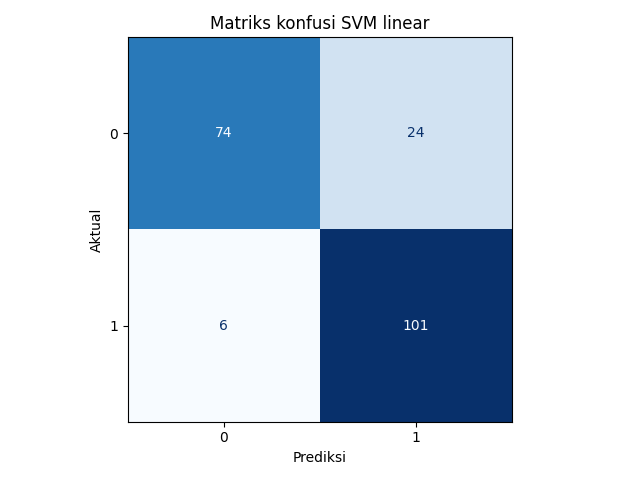

In [8]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', colorbar=False)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Matriks konfusi SVM linear')
plt.tight_layout()
plt.show()